# Поиск оптимальной стратегии методом Q-обучения

Реализуем поиск оптимальной стратегии по TD методу Q-обучения. Для этого сформируем потомка абстрактного класса "табличного" агента.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
import pickle

from abc import ABC, abstractmethod
from collections import defaultdict


class QTableAgent(ABC):
    def __init__(self, env, eps = 0.1, alpha = 0.1):
        self.nA = env.action_space.n # число действий
        self.N = defaultdict(lambda: np.zeros(self.nA))
        # заполняемая таблица значений Q-функции, хранящая ценности пар состояние-действие
        self.Q = defaultdict(lambda: np.zeros(self.nA))
    
        self.eps = eps   
        self.alpha = alpha

    # выбор eps-жадного действия        
    def reset(self):
        self.N = defaultdict(lambda: np.zeros(self.nA))
        self.Q = defaultdict(lambda: np.zeros(self.nA))

    # выбор eps-жадного действия        
    def get_action(self, state):
        if np.random.rand() < self.eps:
            return np.random.choice(self.nA)
        return self.best_action(state)
    
    # выбор жадного действия        
    def best_action(self, state):
        return np.argmax(self.Q[state])

    def get_Q(self, state, act):
        return self.Q[state][act]

    def update_Q(self, state, act, goal):
        # обновление оценки по методу выборочного среднего или с постоянным шагом обновления
        if self.alpha is None:
            self.N[state][act] += 1
            self.Q[state][act] += (goal - self.Q[state][act])/self.N[state][act]
        else:
            self.Q[state][act] += self.alpha*(goal - self.Q[state][act])

    @abstractmethod
    def learn(self):
        """Метод обучения"""
        pass

    def play(self, env, n_episodes):
        """Оценка качества обученного агента. """
        for _ in tqdm(range(n_episodes)):
            state, _ = env.reset()
            while True:
                # выбираем лучшие действия
                action = self.best_action(state)
                state, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    break

    def save_Q(self, name):
        os.makedirs('savedModels', exist_ok=True)
        with open('savedModels/TableAgent_'+name+".pkl",'wb') as f:
            pickle.dump(dict(self.Q), f)
        return 'savedModels/TableAgent_'+name+".pkl"
        
    def load_Q(self, name):
        self.reset()
        with open(name, 'rb') as f:
            loaded_data = pickle.load(f)
            self.Q = defaultdict(lambda: np.zeros(self.nA), loaded_data) 

Алгоритм обучения реализован в методе `learn()`, основное отличие от метода SARSA в формировании цели обновления.

In [2]:
from dataclasses import dataclass

@dataclass
class ConfigTD:
    gamma: float = 0.99
    eps_start: float = 1.0
    eps_decay: float = 0.999
    eps_min: float = 0.01
    alpha_start: float = 0.1
    alpha_decay: float = 1.0
    alpha_min: float = 0.05

class QL_Agent(QTableAgent): 
    def __init__(self, env, config = None):
        super().__init__(env)
        if config is None:
            self.config = ConfigTD()
        else:
            self.config = config
            
        self.env = env
        self.alpha = self.config.alpha_start
        self.eps = self.config.eps_start
        self.gamma = self.config.gamma

    def learn(self, n_episodes = 1000, restart = True):
        if restart == True:
            self.alpha = self.config.alpha_start
            self.eps = self.config.eps_start 
            self.reset()

        # ===== работа алгоритма обучения  =====
        for i in tqdm(range(n_episodes)):
            state, _ = env.reset()
            # запускаем эпизод взаимодействия со средой        
            while True:
                action = agent.get_action(state)
                next_state, reward, terminated, truncated, _ = self.env.step(action)    
                ### !!! основное отличие ###
                best_action = agent.best_action(next_state)           
                upd_goal = reward + (1-terminated) * self.gamma * self.get_Q(next_state, best_action)
                agent.update_Q(state, action, upd_goal)
                  
                if terminated or truncated:
                    break
                state = next_state
                
            # уменьшение доли шагов исследования
            self.eps = max(self.eps * self.config.eps_decay, self.config.eps_min)         
            if self.alpha is not None:
                self.alpha = max(self.alpha * self.config.alpha_decay, self.config.alpha_min)   

### Пример 1

Рассмотрим снова задачу о клеточном мире с утёсом `CliffWalking-v1` и найдём оптимальную стратегию методом Q-learning.

In [3]:
import gymnasium as gym

# Создание среды
env = gym.make('CliffWalking-v1')
n_episodes = 1000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 1.0, 
                eps_decay = 0.95, 
                eps_min = 0.001,                
                alpha_start = 0.25, 
                alpha_decay = 1.0, 
                alpha_min = 0.01
               )

# создание табличного агента
agent = QL_Agent(env, config)


# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 1000/1000 [00:00<00:00, 1632.41it/s]


Выведем график доходов за эпизоды, полученных в взаимодействия агента со средой.

In [4]:
import matplotlib.pyplot as plt
# для того, чтобы избежать ошибок при построении графиков
#import os
#os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

# в названии графика среднее вознаграждение за 20 последних эпизодов
def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(-100, 0)
    plt.show()

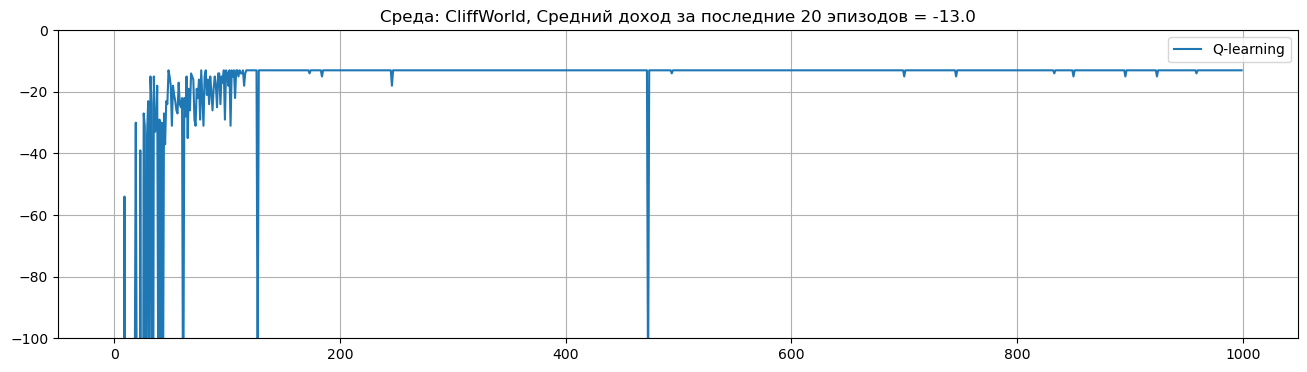

In [5]:
# график доходов
returns = np.array(env.return_queue)
plot_rewards("CliffWorld", returns, 'Q-learning')

График доходов по эпизодам показывает, что уже к 200 эпизоду агент достиг фиксированной стратегии. Общий доход оптимален. Рассмотрим стратегию, которой обучился агент.

In [7]:
import time
from IPython.display import clear_output

env = gym.make("CliffWalking-v1", render_mode='ansi')

state, _ = env.reset()
print(env.render())

while True:
    state, reward, terminated, truncated, _ = env.step(agent.best_action(state)) 
    
    time.sleep(.2)
    clear_output(wait=True)
    print(env.render())

    if terminated or truncated:
        break
    
env.close()

o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  x




В отличие от SARSA, целевая стратегия детерминированная, в ней нет исследования и нет шанса свалиться с утёса. Агент действительно научился кратчайшему пути вдоль утёса.

Продемострируем также тот эффект, что агент обучается даже, когда взаимодействие идёт по исследовательской стратегии.

In [6]:
env = gym.make('CliffWalking-v1')
n_episodes = 1000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 0.5, 
                eps_decay = 1.0, 
                eps_min = 0.001,                
                alpha_start = 0.25, 
                alpha_decay = 1.0, 
                alpha_min = 0.01
               )

# создание табличного агента
agent = QL_Agent(env, config)


# обучение агента БЕЗ СНИЖЕНИЯ eps
agent.learn(n_episodes = n_episodes)

100%|██████████| 1000/1000 [00:01<00:00, 680.77it/s]


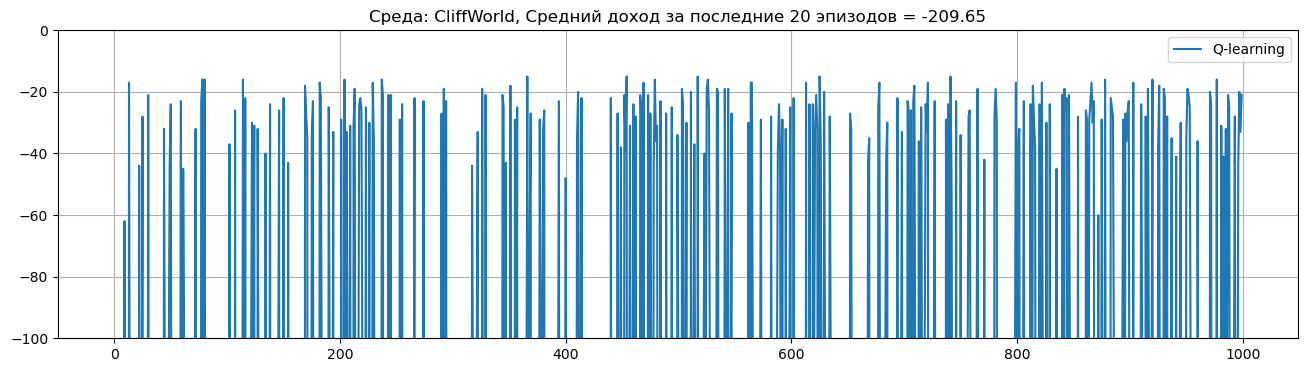

In [7]:
# график доходов
returns = np.array(env.return_queue)
plot_rewards("CliffWorld", returns, 'Q-learning')

В ходе взаимодействия агент показывает не слишком хороший результат. Но тем не менее он уже обучился оптимальной стратегии.

In [8]:
import time
from IPython.display import clear_output

env = gym.make("CliffWalking-v1", render_mode = 'ansi')
env = gym.wrappers.RecordEpisodeStatistics(env)

state, _ = env.reset()
print(env.render())

while True:
    state, reward, terminated, truncated, _ = env.step(agent.best_action(state)) 
    
    time.sleep(.2)
    clear_output(wait=True)
    print(env.render())

    if terminated or truncated:
        break
    
env.close()
print("Доход равен ", env.return_queue[-1])

o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  x


Доход равен  -13.0


Итоговый доход действительно оптимален.

### Пример 2

Применим метод Q-learning для решения задачи о такси `Taxi-v4`.

In [12]:
import gymnasium as gym

# Создание среды
env = gym.make('Taxi-v4')
n_episodes = 5000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 0.5, 
                eps_decay = 1.0, 
                eps_min = 0.001,                
                alpha_start = 0.25, 
                alpha_decay = 1.0, 
                alpha_min = 0.01
               )

# создание табличного агента
agent = QL_Agent(env, config)


# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 5000/5000 [00:06<00:00, 769.88it/s]


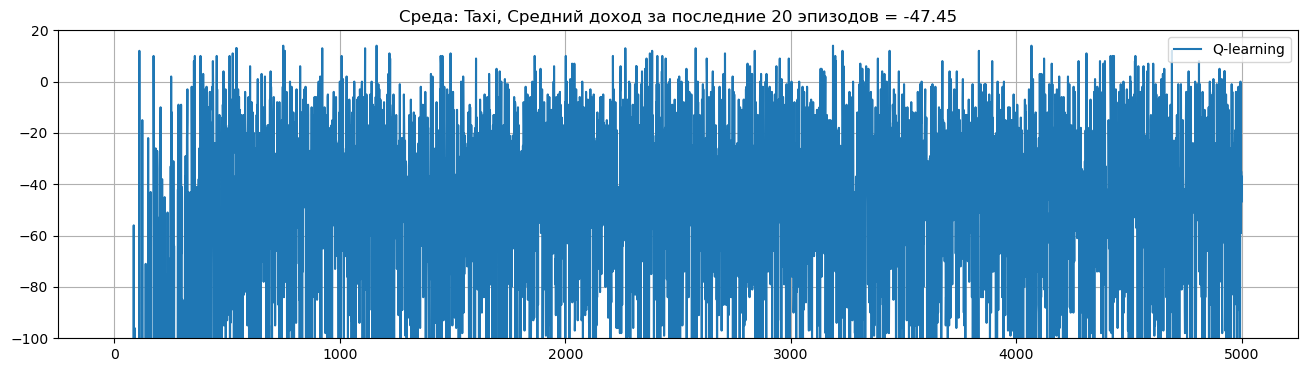

In [13]:
# в названии графика среднее вознаграждение за 20 последних эпизодов
def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(-100, 20)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("Taxi", returns, 'Q-learning')

График вознаграждений выводится для фактически полученных вознаграждений из траекторий, генерируемых по eps-жадной стратегии. Сам агент уже обучился оптимальной стратегии действий. В этом можно убедиться в симуляции.

In [14]:
n_episodes = 10000
env = gym.make("Taxi-v4")
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

agent.play(env, n_episodes)

100%|██████████| 10000/10000 [00:02<00:00, 3607.50it/s]


Средний доход за эпизод равен: 7.9371
Минимальный доход за эпизод равен: 3.0
Максимальный доход за эпизод равен: 15.0


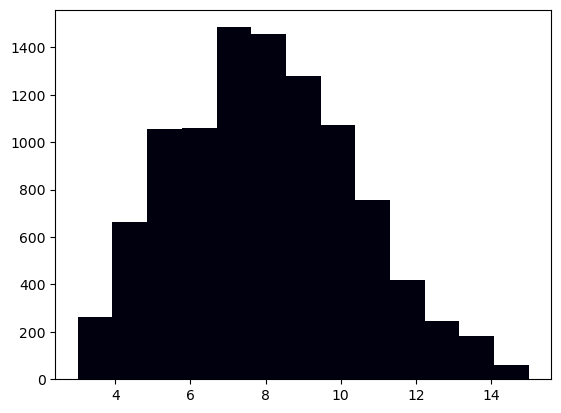

In [15]:
print('Средний доход за эпизод равен:', np.mean(env.return_queue))
print('Минимальный доход за эпизод равен:', np.min(env.return_queue))
print('Максимальный доход за эпизод равен:', np.max(env.return_queue))

import matplotlib.pyplot as plt
plt.hist(env.return_queue, bins=13, color='#00000f')
plt.show()

### Пример 3

Применим метод Q-learning для задачи `FrozenLake`.

In [17]:
import gymnasium as gym

# Создание среды
env = gym.make("FrozenLake-v1")
n_episodes = 10000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 0.5, 
                eps_decay = 0.999,              
                alpha_start = 0.1, 
               )

# создание табличного агента
agent = QL_Agent(env, config)


# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 10000/10000 [00:06<00:00, 1489.80it/s]


Отметим, что при `gamma=1` агент не будет стремиться быстрее завершить эпизод, в итоге полученная стратегия будет просто избегать попадания в ямы.

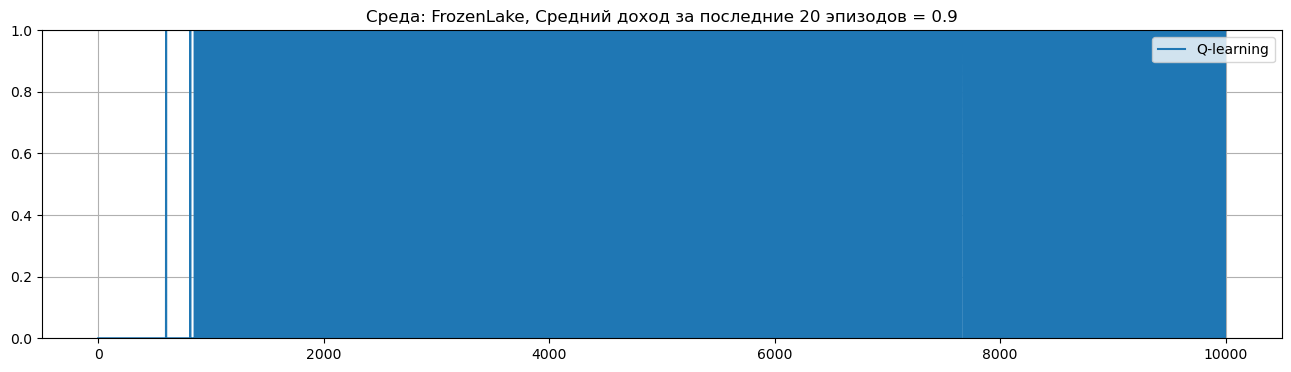

In [18]:
import matplotlib.pyplot as plt
# для того, чтобы избежать ошибок при построении графиков
#import os
#os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"
# в названии графика среднее вознаграждение за 20 последних эпизодов
def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(0, 1)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("FrozenLake", returns, 'Q-learning')

График вознаграждений выводится для фактически полученных вознаграждений из траекторий, генерируемых по eps-жадной стратегии. Сам агент уже обучился оптимальной стратегии действий. В этом можно убедиться в симуляции.

In [19]:
n_episodes = 1000
env = gym.make("FrozenLake-v1", max_episode_steps = 1000)
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

agent.play(env, n_episodes)

100%|██████████| 1000/1000 [00:00<00:00, 1685.44it/s]


In [20]:
print('Средний доход за эпизод равен:', np.mean(env.return_queue))

Средний доход за эпизод равен: 0.79


Действительно, среднее вознаграждение показывает среднее число успешно завершённых эпизодов, почти 83%. 

Ниже можно запустить визулизацию действий агента.

In [21]:
from time import sleep
from IPython.display import clear_output

env = gym.make("FrozenLake-v1", render_mode = 'ansi', max_episode_steps = 1000)
env = gym.wrappers.RecordEpisodeStatistics(env)

state, _ = env.reset()
print(env.render())

while True:
    state, reward, terminated, truncated, _ = env.step(agent.best_action(state)) # выбрать действие случайно
    
    time.sleep(.1)
    clear_output(wait=True)      
    print(env.render())
    if terminated or truncated:
        break
    
env.close()
print("Доход равен ", env.return_queue[-1])

  (Down)
SFFF
FHFH
FFFH
HFFG

Доход равен  1.0


Можно также вытащить обученную стратегию более наглдяно с помощью кода ниже.

In [23]:
optPolicy = dict((k,agent.best_action(k)) for k, v in list(agent.Q.items()))

action_labels = {0:"←", 1:"↓", 2: "→", 3:"↑"}
optimal_actions=[0]*16
for i in range(4):
    for j in range(4):
        if 4*i+j in optPolicy:
            optimal_actions[4*i+j] = action_labels[optPolicy[4*i+j]]
        else:
            optimal_actions[4*i+j] = "ANY"


print("Стратегия:\n",np.array(optimal_actions).reshape((4,4)))

Стратегия:
 [['←' '↑' '←' '←']
 ['←' '←' '→' '←']
 ['↑' '↓' '←' '←']
 ['←' '→' '↓' '←']]


Полученная стратегия соответствует оптимальной стратегии, найденной в методами ДП.

Ниже можно посмотреть на значения обученной Q-функции.

In [24]:
agent.Q

defaultdict(<function __main__.QTableAgent.reset.<locals>.<lambda>()>,
            {1: array([0.27501637, 0.22196362, 0.19664303, 0.42556552]),
             0: array([0.57242388, 0.47883594, 0.48265698, 0.47886411]),
             4: array([0.62339839, 0.29836919, 0.34036108, 0.31483465]),
             8: array([0.31253319, 0.49692727, 0.47315528, 0.67107566]),
             9: array([0.48488549, 0.72957183, 0.31507453, 0.48185118]),
             5: array([0., 0., 0., 0.]),
             12: array([0., 0., 0., 0.]),
             10: array([0.81192383, 0.28215124, 0.36716933, 0.30827264]),
             6: array([0.17188688, 0.12002265, 0.29048307, 0.14288802]),
             2: array([0.35813379, 0.31013902, 0.24943837, 0.26914675]),
             3: array([0.08510046, 0.        , 0.        , 0.        ]),
             7: array([0., 0., 0., 0.]),
             13: array([0.5224298 , 0.61162842, 0.80942236, 0.57326487]),
             14: array([0.71379379, 0.90310562, 0.76678589, 0.72174658]),

#### Дополнительная визуализация процесса обучения

Ниже проведена визуализация эволюции изменений значений Q-функции.

In [30]:
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation

# Создаём анимацию
anim = animate_learning(Q_history, episodes_log, save_gif=False, gif_filename='frozenlake_learning1.gif', interval=200)

# Отображаем в ноутбуке
from IPython.display import HTML
HTML(anim.to_jshtml())

Код для построения визуализации.

In [26]:
from tqdm import tqdm
    
# алгоритм обучения, возврат: массив доходов
def QLearning_viz(env, agent, n_episodes=10000, gamma = 0.99, 
                      eps_start=1.0, eps_decay = 0.999, eps_min = 0.01, record_every=200, env_shape = (4,4)):
    
    agent.eps = eps_start
    history = []
    episodes_log = []  # номера эпизодов, когда делали снимок
    
    for i in tqdm(range(n_episodes)):
        state, _ = env.reset()
        # запускаем эпизод взаимодействия со средой        
        while True:
            action = agent.get_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            
            best_action = agent.best_action(next_state)           
            upd_goal = reward + gamma * agent.Q[next_state][best_action]
            agent.update_Q(state, action, upd_goal)
            
            state = next_state
            if terminated or truncated:
                break
        # уменьшение доли шагов исследования
        agent.eps = max(agent.eps * eps_decay, eps_min)     

        if (i + 1) % record_every == 0 or i == 0 or i == n_episodes - 1:
            # Создаём снимок в виде готовых сеток
            snapshot = {}
            for a in range(agent.nA):
                snapshot[f'Q{a}'] = get_state_grid(agent.Q, action=a, value_type='Q', shape=env_shape)
            snapshot['V'] = get_state_grid(agent.Q, value_type='V', shape=env_shape)
            snapshot['pi'] = get_state_grid(agent.Q, value_type='pi', shape=env_shape)
            history.append(snapshot)
            episodes_log.append(i + 1)

    return history, episodes_log



  # ---------- Вспомогательная функция для преобразования Q в сетку ----------
def get_state_grid(Q, action=None, value_type='Q', shape=(4,4)):
    action_labels = {0:"←", 1:"↓", 2: "→", 3:"↑"}
    grid = np.zeros(shape, dtype=float)
    n_states = shape[0] * shape[1]
    for s in range(n_states):
        row, col = divmod(s, shape[1])
        if value_type == 'Q':
            grid[row, col] = Q[s][action]
        elif value_type == 'V':
            grid[row, col] = np.max(Q[s])
        elif value_type == 'pi':
            grid[row, col] = np.argmax(Q[s])
    if value_type == 'pi':
        return grid.astype(int)
    return grid  

In [27]:
import gymnasium as gym
# Создание среды
env = gym.make("FrozenLake-v1")
n_episodes = 4000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 1.0, 
                eps_decay = 0.999,              
                alpha_start = 0.01, 
               )

# создание табличного агента
agent = QL_Agent(env, config)
agent.alpha = 0.1
# обучение агента и получение доходов по эпизодам
Q_history, episodes_log = QLearning_viz(env, agent, n_episodes = n_episodes)

100%|██████████| 4000/4000 [00:02<00:00, 1871.01it/s]


In [28]:
n_episodes = 1000
env = gym.make("FrozenLake-v1", max_episode_steps = 1000)
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

agent.play(env, n_episodes)
print('Средний доход за эпизод равен:', np.mean(env.return_queue))

100%|██████████| 1000/1000 [00:00<00:00, 1469.84it/s]

Средний доход за эпизод равен: 0.81


In [29]:
import seaborn as sns
def animate_learning(history, episodes, env_shape=(4,4), actions_names=['←', '↓', '→', '↑'],
                     save_gif=False, gif_filename='learning.gif', interval=300):
    # Глобальные min/max для фиксации шкал
    all_Q = {a: [] for a in range(4)}
    all_V = []
    for snap in history:
        for a in range(4):
            all_Q[a].extend(snap[f'Q{a}'].flatten())
        all_V.extend(snap['V'].flatten())
    vmin_Q = {a: np.min(all_Q[a]) for a in range(4)}
    vmax_Q = {a: np.max(all_Q[a]) for a in range(4)}
    vmin_V, vmax_V = np.min(all_V), np.max(all_V)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle('Обучение Q-learning на FrozenLake', fontsize=16)

    def draw_frame(frame):
        snap = history[frame]
        # Очищаем все оси
        for ax in axes.flat:
            ax.clear()
        # Заголовок
        fig.suptitle(f'Обучение Q-learning – эпизод {episodes[frame]}', fontsize=16)

        # Рисуем Q для каждого действия
        for a in range(4):
            row, col = divmod(a, 3)
            ax = axes[row, col]
            grid = snap[f'Q{a}']
            sns.heatmap(grid, annot=True, fmt=".2f", cmap='Greys',
                        vmin=vmin_Q[a], vmax=vmax_Q[a],
                        cbar=False, ax=ax, square=True,
                        xticklabels=False, yticklabels=False)
            ax.set_title(f'Q(s, {actions_names[a]})')

            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(1)
                spine.set_color('black')

        # V
        ax_v = axes[1, 1]
        v_grid = snap['V']
        sns.heatmap(v_grid, annot=True, fmt=".2f", cmap='Greys',
                    vmin=vmin_V, vmax=vmax_V,
                    cbar=False, ax=ax_v, square=True,
                    xticklabels=False, yticklabels=False)
        ax_v.set_title('V(s) = max_a Q(s,a)')

        for spine in ax_v.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1)
            spine.set_color('black')

        # Политика
        ax_pi = axes[1, 2]
        pi_grid = snap['pi']
        sns.heatmap(pi_grid, annot=True, fmt="d", cmap='Greys',
                    cbar=False, ax=ax_pi, square=True,
                    xticklabels=False, yticklabels=False)
        ax_pi.set_title('π(s) = argmax Q(s,a)')

        for spine in ax_pi.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1)
            spine.set_color('black')

        return axes.flat

    anim = FuncAnimation(fig, draw_frame, frames=len(history), interval=interval, blit=False)

    if save_gif:
        anim.save(gif_filename, writer='pillow')
        print(f"Анимация сохранена как {gif_filename}")

    plt.close(fig)
    return anim